# Fair comparison: E3SMv3-4DEnVarLnd vs. the other hindcast experiments (01 + 03 metrics)

**Temporary analysis notebook.** E3SMv3-4DEnVarLnd only has May starts for 1980–1989, while the other
experiments cover 1980–1995 or longer. Skill computed over different start years is not comparable, so this
notebook re-scores **every** experiment on exactly the same footing:

| Fairness rule | Setting |
|---|---|
| Initialization cohort | May starts, 1980–1989 (10 years), identical for every experiment |
| Lead-dependent drift and observed climatology | 1980–1989 (same convention as 1a/3a: climatology = run years) |
| Ensemble size | 10 members everywhere; CESM2-SMYLE (20 members) is scored as the mean over random 10-member subsets |
| Grid / observations (01) | 5°×5° conservative regridding; ERA5 (TS, TREFHT, PSL) or GPCP v2.3 (PRECT), as in `1a_atm_leadtime_acc_skill_map.ipynb` |
| Observations (03) | HadISST2 regional SST indices, as in `3a_sst_skill_ts.ipynb` |
| Detrending | linear detrend before scoring (`DETREND`) |
| Uncertainty | ensemble-member bootstrap (members drawn with replacement), 5–95 % range |

Metrics reproduced with the same `esp_lab` routines as the production notebooks:

* **01** (`1a_atm`): seasonal ACC and nRMSE maps per lead, area-averaged ACC/nRMSE vs. lead for
  global / land / ocean / tropics, and 4DEnVarLnd-minus-experiment ACC difference maps.
* **03** (`3a_sst`): seasonal ACC and nRMSE of regional SST indices (Niño3.4, Niño3, …) vs. lead.
* A final scorecard summarizes 4DEnVarLnd minus each experiment.

**Read with care:** ten start years is a very small sample. For n = 10 an ACC must exceed roughly 0.55 to be
significant at p < 0.1, and differences of ±0.2 between experiments are well within sampling noise. Use the
bootstrap ranges and the consistency across fields/leads/regions rather than single numbers.

Inputs are reused where they already exist (1a seasonal input caches, 1a observation caches, 3a SST-index
series, in the test root first and then the production root, read-only). Anything missing, e.g. the
4DEnVarLnd inputs, is built from the raw archive and written under the **test** data root. Figures go to
`<test figure root>/sample_figures/`; no web gallery is written.

In [1]:
# Test-run output roots (set before importing esp_lab so every module sees them).
import os
os.environ["ESP_LAB_FIGURE_ROOT"] = "/global/cfs/cdirs/e3sm/www/zhan391/e3sm-s2d_test"
os.environ["ESP_LAB_S2D_DIAG_ROOT"] = "/global/cfs/cdirs/e3sm/S2S2D/s2d_diag/tmp/e3sm-s2d_test"
os.environ["ESP_LAB_FIGURE_GALLERY"] = "0"  # test runs: figures only, no figures.json/index.html

%matplotlib inline
import importlib.util
import logging
from pathlib import Path
from types import SimpleNamespace

import cftime
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import cartopy.crs as ccrs
from cartopy.util import add_cyclic_point

from esp_lab import env_paths, stats, index_reference_skill
from esp_lab import data_access_e3sm as data_access
from esp_lab import data_access_cesm_smyle as smyle_access
from esp_lab.leadtime_workflow import compute_skill_lead_range, compute_skill_lead_range_batch
from esp_lab.utils import calendar_utils as cal
from esp_lab.utils import regrid_utils as regrid
from esp_lab.utils.filename_utils import resolve_year_span_path, sst_index_filename
from esp_lab.utils.netcdf_utils import atomic_to_netcdf, load_netcdf
from esp_lab.utils.unit_conversion import (
    convert_kelvin_to_celsius, convert_pa_to_hpa, convert_precip_mps_to_mmday, no_unit_conversion,
)
from esp_lab.utils.dask_util import DaskConfig, get_cluster_client
from esp_lab.utils.notebook_resources import restart_notebook_cluster, close_notebook_resources

In [2]:
# =============================================================================
# CONFIGURATION BLOCK: Edit settings here
# =============================================================================
INIT_MONTH = 5
YEARS = (1980, 1989)                 # common initialization cohort (4DEnVarLnd coverage)
CLIMATOLOGY_YEARS = YEARS            # drift + observed climatology window (1a/3a convention)
DETREND = True
NENS = 10                            # E3SM members; CESM2-SMYLE is subsampled to this size
NLEAD = 24                           # monthly leads in every hindcast
FOCUS_CASE = "E3SM-4DEnVarLnd"       # experiment the difference figures and scorecard are built around

# Experiments compared (all must cover May 1980-1989). Plot order = dict order.
EXPERIMENTS = {
    "E3SM-FOSIRL": dict(case_prefix="WCYCL20TR_ne30pg2_r05_IcoswISC30E3r5_JRA55_FOSIRL",
                        cache_tag="JRA55_FOSIRL", label="E3SMv3-FOSIRL", color="black", ls="-", marker="o"),
    "E3SM-Reanalysis": dict(case_prefix="WCYCL20TR_ne30pg2_r05_IcoswISC30E3r5_BruteForce",
                            cache_tag="Reanalysis", label="E3SMv3-Reanalysis", color="tab:blue", ls="-", marker="o"),
    "E3SM-4DEnVarOcn": dict(case_prefix="WCYCL20TR_ne30pg2_r05_IcoswISC30E3r5_4DEnVarOcn",
                            cache_tag="4DEnVarOcn", label="E3SMv3-4DEnVarOcn", color="tab:purple", ls="-", marker="o"),
    "E3SM-4DEnVarOcn-OLD": dict(case_prefix="4DEnVarOcn.OLD/WCYCL20TR_ne30pg2_r05_IcoswISC30E3r5_4DEnVarOcn",
                                cache_tag="4DEnVarOcn-OLD", label="E3SMv3-4DEnVarOcn (old)", color="tab:purple", ls="--", marker="o"),
    "E3SM-4DEnVarLnd": dict(case_prefix="WCYCL20TR_ne30pg2_r05_IcoswISC30E3r5_4DEnVarLnd",
                            cache_tag="4DEnVarLnd", label="E3SMv3-4DEnVarLnd", color="tab:green", ls="-", marker="o"),
}
INCLUDE_SMYLE = True
SMYLE = dict(cache_tag="CESM-SMYLE", label="CESM2-SMYLE (10-mem)", color="tab:orange", ls="--", marker="s", nens=20)
SMYLE_BENCHMARK_DIR = Path("/global/cfs/cdirs/e3sm/S2S2D/s2d_diag/CESM-SMYLE")  # read-only gridded benchmark

# Resampling: SMYLE 10-member subsets (without replacement) and member bootstrap (with replacement).
N_SMYLE_SUBSETS = 50
N_BOOTSTRAP = 200
BOOT_PERCENTILES = (5, 95)
RANDOM_SEED = 42

# ---- 01: gridded atmosphere fields (as in 1a_atm_leadtime_acc_skill_map) ----
ATM_FIELDS = ["TS", "TREFHT", "PRECT", "PSL"]
FIELD_INFO = {
    "TS":     dict(name="Surface temperature",     convert=convert_kelvin_to_celsius),
    "TREFHT": dict(name="2-m air temperature",     convert=convert_kelvin_to_celsius),
    "PRECT":  dict(name="Precipitation",           convert=convert_precip_mps_to_mmday),
    "PSL":    dict(name="Sea-level pressure",      convert=convert_pa_to_hpa),
}
AREA_REGIONS = {                      # (lat0, lat1, surface)
    "Global 60S-80N": (-60.0, 80.0, "all"),
    "Land 60S-80N":   (-60.0, 80.0, "land"),
    "Ocean 60S-60N":  (-60.0, 60.0, "ocean"),
    "Tropics 20S-20N": (-20.0, 20.0, "all"),
}
MAP_LEADS = 4                         # first N seasonal leads drawn on the map figures
SIG_LEVEL = 0.1                       # dots: ACC significant at p < SIG_LEVEL
DLAT = DLON = 5.0

# ---- 03: regional SST indices (as in 3a_sst_skill_ts) ----
# TNI/RONI are omitted by default: they are standardized/scaled with a climatology-dependent
# factor, so caches built with different climatologies would not be strictly comparable.
SST_INDICES = ["Nino3.4", "Nino3", "Nino4", "Nino12", "ONI", "IOD", "TNA", "TSA", "AtlNino", "AtlMDR"]
SST_FIELD = "TS"                      # 3a default for E3SM and CESM-SMYLE

FORCE_REBUILD = False                 # True rebuilds this notebook's 5x5 caches and SST-index series
DASK_WORKERS = 8
# ===== END CONFIGURATION BLOCK =====

S2D_DIAG_ROOT = env_paths.s2d_diag_root()                    # writes (test root)
PRODUCTION_DIAG_ROOT = Path("/global/cfs/cdirs/e3sm/S2S2D/s2d_diag")
READ_ROOTS = list(dict.fromkeys([S2D_DIAG_ROOT, PRODUCTION_DIAG_ROOT]))  # reuse order
RAW_MODEL_ROOT = str(env_paths.raw_model_root())
FIGURE_DIR = env_paths.figure_root() / "sample_figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR = S2D_DIAG_ROOT / "multimodel" / "fair_compare"
TABLE_DIR.mkdir(parents=True, exist_ok=True)

YEAR_LIST = list(range(YEARS[0], YEARS[1] + 1))
INIT_TAGS = list(data_access.build_init_tags(YEAR_LIST, INIT_MONTH))
CLIM0, CLIM1 = CLIMATOLOGY_YEARS
CLIM_START = cftime.DatetimeNoLeap(CLIM0, 1, 1)
CLIM_END = cftime.DatetimeNoLeap(CLIM1, 12, 31)
SPAN = f"y{YEARS[0]}-{YEARS[1]}"
FOCUS_TAG = EXPERIMENTS[FOCUS_CASE]["cache_tag"]

SOURCES = dict(EXPERIMENTS)
if INCLUDE_SMYLE:
    SOURCES["CESM-SMYLE"] = SMYLE
print(f"Cohort: May {YEARS[0]}-{YEARS[1]} ({len(YEAR_LIST)} starts); climatology {CLIM0}-{CLIM1}; detrend={DETREND}")
print(f"Write root: {S2D_DIAG_ROOT}\nRead roots: {[str(r) for r in READ_ROOTS]}\nFigures: {FIGURE_DIR}")

Cohort: May 1980-1989 (10 starts); climatology 1980-1989; detrend=True
Write root: /global/cfs/cdirs/e3sm/S2S2D/s2d_diag/tmp/e3sm-s2d_test
Read roots: ['/global/cfs/cdirs/e3sm/S2S2D/s2d_diag/tmp/e3sm-s2d_test', '/global/cfs/cdirs/e3sm/S2S2D/s2d_diag']
Figures: /global/cfs/cdirs/e3sm/www/zhan391/e3sm-s2d_test/sample_figures


In [3]:
dask_cfg = DaskConfig(cluster_type="local", workers=DASK_WORKERS)
cluster, client, workflow_resources = restart_notebook_cluster(globals(), lambda: get_cluster_client(dask_cfg))
cluster

Scheduler: tcp://127.0.0.1:44325
Connected workers: 5
Dashboard: http://127.0.0.1:8787/status


LocalCluster(4da5ce41, 'tcp://127.0.0.1:44325', workers=8, threads=8, memory=29.80 GiB)

In [4]:
# -----------------------------------------------------------------------------
# Shared helpers: lead labels, member resampling, plotting style
# -----------------------------------------------------------------------------
SEASON_OF_CENTER = {1: "DJF", 4: "MAM", 7: "JJA", 10: "SON"}


def lead_labels(valid_time):
    # Season name + year offset from the start year, e.g. JJA0, DJF1.
    t = valid_time.isel(Y=0).values
    y0 = int(str(valid_time.Y.values[0])[:4])
    return [f"{SEASON_OF_CENTER.get(v.month, f'm{v.month:02d}')}{v.year - y0}" for v in t]


_rng = np.random.default_rng(RANDOM_SEED)
SMYLE_SUBSETS = np.array([_rng.choice(SMYLE["nens"], NENS, replace=False) for _ in range(N_SMYLE_SUBSETS)])
BOOT_INDICES = {n: _rng.integers(0, n, size=(N_BOOTSTRAP, NENS)) for n in {NENS, SMYLE["nens"]}}


def style(key):
    s = SOURCES[key]
    return dict(color=s["color"], linestyle=s["ls"], marker=s["marker"], label=s["label"])


def save(fig, name):
    path = FIGURE_DIR / name
    fig.savefig(path, dpi=200, bbox_inches="tight")
    print(f"Saved {path}")

## Part 01 — gridded seasonal ACC / nRMSE (1a metrics)

Each experiment's seasonal field for the common cohort is regridded to 5°×5° once and cached under
`<test root>/<case>/leadtime_acc/fair_compare/atm/<field>/` (pre-drift values, observation units).

In [5]:
# -----------------------------------------------------------------------------
# Build or reuse the 5x5 seasonal fields for every source and field
# -----------------------------------------------------------------------------
DESTGRID = regrid.make_latlon_grid(dlat=DLAT, dlon=DLON)
_regridders = {}


def _regrid(ds, var):
    key = (ds.sizes["lat"], ds.sizes["lon"], float(ds.lat[0]), float(ds.lon[0]))
    if key not in _regridders:
        _regridders[key] = regrid.make_regridder(ds, DESTGRID, method="conservative", periodic=True)
    return _regridders[key](ds[var])


def _fair_cache_path(tag, field, nens):
    return (S2D_DIAG_ROOT / tag / "leadtime_acc" / "fair_compare" / "atm" / field
            / f"{tag}_init{INIT_MONTH:02d}_{field}_{SPAN}_N{nens:02d}_M{NLEAD:02d}_5x5deg_seas.nc")


def _e3sm_native_seasonal(info, field):
    # Reuse a 1a seasonal input cache covering the cohort, else read the raw archive.
    tag = info["cache_tag"]
    for root in READ_ROOTS:
        folder = root / tag / "leadtime_acc" / "inputs" / "atm" / field
        for path in sorted(folder.glob(f"{tag}_init{INIT_MONTH:02d}_{field}_y*_exnone_N{NENS:02d}_M{NLEAD:02d}_seas.nc")):
            ds = xr.open_dataset(path, chunks={})
            if (ds.attrs.get("cache_kind") == "seasonal_e3sm_input" and ds.sizes.get("M") == NENS
                    and set(INIT_TAGS) <= set(map(str, ds.Y.values))):
                return ds.sel(Y=INIT_TAGS), str(path)
            ds.close()
    print(f"  {tag} {field}: no reusable 1a input; reading the raw archive")
    raw = data_access.get_monthly_data(
        data_dir=RAW_MODEL_ROOT, case_prefix=info["case_prefix"],
        members=[f"EN{i:02d}" for i in range(NENS)], init_tags=INIT_TAGS, field=field,
        nlead=NLEAD, chunks={}, realm="atm", grid="180x360_aave", freq="monthly", ts_split="2yr",
        require_all_members=True, verify_field_name=True, verify_coverage=True, engine="netcdf4",
    ).chunk({"Y": 3, "L": 24, "M": 2, "lat": 90, "lon": 180})
    return cal.mon_to_seas_dask(raw), f"raw archive {RAW_MODEL_ROOT}/{info['case_prefix']}_*"


def _smyle_native_seasonal(field):
    ds = smyle_access.load_benchmark(field=field, init_month=INIT_MONTH, benchmark_dir=SMYLE_BENCHMARK_DIR,
                                     nens=SMYLE["nens"], nlead=NLEAD, freq="seas",
                                     chunks={"Y": 3, "L": -1, "M": 2, "lat": 96, "lon": 144})
    path = smyle_access.benchmark_path(field, INIT_MONTH, SMYLE_BENCHMARK_DIR, nens=SMYLE["nens"], nlead=NLEAD)
    return ds.sel(Y=INIT_TAGS), str(path)


def fair_seasonal_field(key, field):
    info = SOURCES[key]
    tag = info["cache_tag"]
    nens = SMYLE["nens"] if key == "CESM-SMYLE" else NENS
    path = _fair_cache_path(tag, field, nens)
    expected = {"fair_compare_version": 1, "field": field, "years": SPAN, "init_month": INIT_MONTH,
                "grid": f"latlon_{DLAT}x{DLON}", "regridding_method": "conservative"}
    if path.is_file() and not FORCE_REBUILD:
        ds = load_netcdf(path)
        if all(str(ds.attrs.get(k)) == str(v) for k, v in expected.items()):
            return ds
        print(f"  {path.name}: attributes changed; rebuilding")
    native, source = _smyle_native_seasonal(field) if key == "CESM-SMYLE" else _e3sm_native_seasonal(info, field)
    da = FIELD_INFO[field]["convert"](_regrid(native, field)).astype("float32")
    out = xr.Dataset({field: da, "time": native["time"]}).compute()
    out.attrs.update(expected, source=source, case_prefix=info.get("case_prefix", "b.e21.BSMYLE.f09_g17"))
    path.parent.mkdir(parents=True, exist_ok=True)
    atomic_to_netcdf(out, path)
    print(f"  wrote {path}")
    return out


def load_observations(field):
    # 1a's prepared 5x5 observation cache (ERA5 or GPCP, observation units).
    for root in READ_ROOTS:
        folder = root / "observations" / "leadtime_acc" / "prepared_skill" / "atm" / field
        for path in sorted(folder.glob(f"*_{field}_seasonal_5x5deg_skill_v1.nc")):
            ds = load_netcdf(path)
            if ds.attrs.get("target_grid") == f"latlon_{DLAT}x{DLON}_periodic-True":
                print(f"  observations: {path}")
                return ds["observation"]
    raise FileNotFoundError(f"No 5x5 observation cache for {field}; run 1a_atm_leadtime_acc_skill_map.ipynb once for {field}.")


seasonal = {field: {} for field in ATM_FIELDS}
observations = {}
for field in ATM_FIELDS:
    print(f"== {field}")
    observations[field] = load_observations(field)
    for key in SOURCES:
        seasonal[field][key] = fair_seasonal_field(key, field)
        print(f"  {key}: {dict(seasonal[field][key][field].sizes)}")

== TS


  observations: /global/cfs/cdirs/e3sm/S2S2D/s2d_diag/tmp/e3sm-s2d_test/observations/leadtime_acc/prepared_skill/atm/TS/ERA5_TS_seasonal_5x5deg_skill_v1.nc
  E3SM-FOSIRL: {'Y': 10, 'L': 8, 'M': 10, 'lat': 37, 'lon': 72}


  E3SM-Reanalysis: {'Y': 10, 'L': 8, 'M': 10, 'lat': 37, 'lon': 72}
  E3SM-4DEnVarOcn: {'Y': 10, 'L': 8, 'M': 10, 'lat': 37, 'lon': 72}


  E3SM-4DEnVarOcn-OLD: {'Y': 10, 'L': 8, 'M': 10, 'lat': 37, 'lon': 72}


  E3SM-4DEnVarLnd: {'Y': 10, 'L': 8, 'M': 10, 'lat': 37, 'lon': 72}
  CESM-SMYLE: {'Y': 10, 'L': 8, 'M': 20, 'lat': 37, 'lon': 72}
== TREFHT


  observations: /global/cfs/cdirs/e3sm/S2S2D/s2d_diag/tmp/e3sm-s2d_test/observations/leadtime_acc/prepared_skill/atm/TREFHT/ERA5_TREFHT_seasonal_5x5deg_skill_v1.nc
  E3SM-FOSIRL: {'Y': 10, 'L': 8, 'M': 10, 'lat': 37, 'lon': 72}
  E3SM-Reanalysis: {'Y': 10, 'L': 8, 'M': 10, 'lat': 37, 'lon': 72}


... (3 outputs left out)

  E3SM-4DEnVarOcn-OLD: {'Y': 10, 'L': 8, 'M': 10, 'lat': 37, 'lon': 72}
  E3SM-4DEnVarLnd: {'Y': 10, 'L': 8, 'M': 10, 'lat': 37, 'lon': 72}


  CESM-SMYLE: {'Y': 10, 'L': 8, 'M': 20, 'lat': 37, 'lon': 72}
== PSL
  observations: /global/cfs/cdirs/e3sm/S2S2D/s2d_diag/tmp/e3sm-s2d_test/observations/leadtime_acc/prepared_skill/atm/PSL/ERA5_PSL_seasonal_5x5deg_skill_v1.nc
  E3SM-FOSIRL: {'Y': 10, 'L': 8, 'M': 10, 'lat': 37, 'lon': 72}


  E3SM-Reanalysis: {'Y': 10, 'L': 8, 'M': 10, 'lat': 37, 'lon': 72}
  E3SM-4DEnVarOcn: {'Y': 10, 'L': 8, 'M': 10, 'lat': 37, 'lon': 72}
  E3SM-4DEnVarOcn-OLD: {'Y': 10, 'L': 8, 'M': 10, 'lat': 37, 'lon': 72}


  E3SM-4DEnVarLnd: {'Y': 10, 'L': 8, 'M': 10, 'lat': 37, 'lon': 72}
  CESM-SMYLE: {'Y': 10, 'L': 8, 'M': 20, 'lat': 37, 'lon': 72}


In [6]:
# -----------------------------------------------------------------------------
# Drift removal + skill: central estimate, SMYLE 10-member subsets, member bootstrap
# -----------------------------------------------------------------------------
def _prepare(ds, field):
    da, time, _ = index_reference_skill.retain_complete_seasonal_leads(ds[field], ds["time"], label=field)
    anom, _ = stats.remove_drift(da, time, CLIM0, CLIM1)
    return anom.load(), time.load()   # 5x5 arrays are small; score in memory


def gridded_skill(key, field):
    anom, time = _prepare(seasonal[field][key], field)
    obs = observations[field]
    nlead = anom.sizes["L"]
    common = dict(detrend=DETREND)
    if key == "CESM-SMYLE":
        central = compute_skill_lead_range_batch(
            anom, time, obs, CLIM_START, CLIM_END, SMYLE_SUBSETS, 1, nlead,
            metrics=("corr", "pval", "rmse"), **common).mean("iteration")
    else:
        central = compute_skill_lead_range(anom, time, obs, CLIM_START, CLIM_END, 1, nlead, resamp=0, **common)
    boot = compute_skill_lead_range_batch(
        anom, time, obs, CLIM_START, CLIM_END, BOOT_INDICES[anom.sizes["M"]], 1, nlead,
        metrics=("corr", "rmse"), **common)
    labels = lead_labels(time)
    return central[["corr", "pval", "rmse"]].compute(), boot.compute(), labels


skill_maps, skill_boot, LEAD_LABELS = {}, {}, {}
for field in ATM_FIELDS:
    skill_maps[field], skill_boot[field] = {}, {}
    for key in SOURCES:
        skill_maps[field][key], skill_boot[field][key], LEAD_LABELS[field] = gridded_skill(key, field)
    print(f"{field}: leads {LEAD_LABELS[field]}")

TS: leads ['JJA0', 'SON0', 'DJF1', 'MAM1', 'JJA1', 'SON1', 'DJF2']


TREFHT: leads ['JJA0', 'SON0', 'DJF1', 'MAM1', 'JJA1', 'SON1', 'DJF2']


PRECT: leads ['JJA0', 'SON0', 'DJF1', 'MAM1', 'JJA1', 'SON1', 'DJF2']


PSL: leads ['JJA0', 'SON0', 'DJF1', 'MAM1', 'JJA1', 'SON1', 'DJF2']


In [7]:
# -----------------------------------------------------------------------------
# Region masks (land fraction from the E3SM Natural-Earth land mask) and area means
# -----------------------------------------------------------------------------
sftlf_path = next(p for root in READ_ROOTS for p in sorted(root.glob("*/fixed/sftlf.E3SM.nc")))
sftlf = xr.open_dataset(sftlf_path)["sftlf"].astype("float64").to_dataset(name="sftlf")
LANDFRAC = regrid.make_regridder(sftlf, DESTGRID, method="conservative", periodic=True)(sftlf["sftlf"]).load()
any_obs = observations[ATM_FIELDS[0]]
LAT, LON = any_obs.lat, any_obs.lon
WEIGHTS = np.cos(np.deg2rad(LAT)).broadcast_like(LANDFRAC)


def region_mask(region):
    lat0, lat1, surface = AREA_REGIONS[region]
    mask = (LAT >= lat0) & (LAT <= lat1)
    if surface == "land":
        mask = mask & (LANDFRAC >= 0.5)
    elif surface == "ocean":
        mask = mask & (LANDFRAC < 0.5)
    return mask.broadcast_like(LANDFRAC)


def area_mean(da, region):
    w = WEIGHTS.where(region_mask(region) & da.notnull())
    return (da * w).sum(("lat", "lon")) / w.sum(("lat", "lon"))


rows = []
area_boot = {}
for field in ATM_FIELDS:
    for region in AREA_REGIONS:
        for key in SOURCES:
            for metric in ("corr", "rmse"):
                central = area_mean(skill_maps[field][key][metric], region)
                boot = area_mean(skill_boot[field][key][metric], region)
                lo, hi = (boot.quantile(q / 100, "iteration") for q in BOOT_PERCENTILES)
                area_boot[(field, region, key, metric)] = (central, lo, hi)
                for i, L in enumerate(central.L.values):
                    rows.append(dict(field=field, region=region, experiment=SOURCES[key]["label"], key=key,
                                     metric={"corr": "ACC", "rmse": "nRMSE"}[metric],
                                     lead=LEAD_LABELS[field][i], L=int(L), value=float(central.sel(L=L)),
                                     p_lo=float(lo.sel(L=L)), p_hi=float(hi.sel(L=L))))
atm_table = pd.DataFrame(rows)
atm_table_path = TABLE_DIR / f"multimodel_init{INIT_MONTH:02d}_atm_area_mean_skill_fair_{SPAN}.csv"
atm_table.to_csv(atm_table_path, index=False)
print(f"Saved {atm_table_path}")

# Lead-averaged area-mean ACC (rows: field/region; columns: experiments)
atm_table[atm_table.metric == "ACC"].pivot_table(
    index=["field", "region"], columns="experiment", values="value", aggfunc="mean", sort=False
).round(2)

Saved /global/cfs/cdirs/e3sm/S2S2D/s2d_diag/tmp/e3sm-s2d_test/multimodel/fair_compare/multimodel_init05_atm_area_mean_skill_fair_y1980-1989.csv


experiment              E3SMv3-FOSIRL  E3SMv3-Reanalysis  E3SMv3-4DEnVarOcn  \
field  region                                                                 
TS     Global 60S-80N            0.22               0.22               0.17   
       Land 60S-80N              0.11               0.14               0.14   
       Ocean 60S-60N             0.26               0.24               0.18   
       Tropics 20S-20N           0.35               0.33               0.31   
TREFHT Global 60S-80N            0.22               0.21               0.18   
       Land 60S-80N              0.12               0.14               0.15   
       Ocean 60S-60N             0.25               0.24               0.19   
       Tropics 20S-20N           0.38               0.35               0.33   
PRECT  Global 60S-80N            0.08               0.10               0.09   
       Land 60S-80N              0.02               0.06               0.08   
       Ocean 60S-60N             0.10               0.11               0.09   
       Tropics 20S-20N           0.14               0.15               0.16   
PSL    Global 60S-80N            0.18               0.21               0.17   
       Land 60S-80N              0.17               0.19               0.17   
       Ocean 60S-60N             0.20               0.23               0.18   
       Tropics 20S-20N           0.35               0.38               0.29   

experiment              E3SMv3-4DEnVarOcn (old)  E3SMv3-4DEnVarLnd  \
field  region                                                        
TS     Global 60S-80N                      0.05              -0.03   
       Land 60S-80N                        0.06              -0.01   
       Ocean 60S-60N                       0.05              -0.03   
       Tropics 20S-20N                     0.09              -0.06   
TREFHT Global 60S-80N                      0.05              -0.02   
       Land 60S-80N                        0.06              -0.01   
       Ocean 60S-60N                       0.05              -0.02   
       Tropics 20S-20N                     0.07              -0.05   
PRECT  Global 60S-80N                      0.04              -0.01   
       Land 60S-80N                        0.02               0.02   
       Ocean 60S-60N                       0.04              -0.01   
       Tropics 20S-20N                     0.07              -0.02   
PSL    Global 60S-80N                      0.07              -0.03   
       Land 60S-80N                        0.09              -0.02   
       Ocean 60S-60N                       0.08              -0.04   
       Tropics 20S-20N                     0.11              -0.06   

experiment              CESM2-SMYLE (10-mem)  
field  region                                 
TS     Global 60S-80N                   0.22  
       Land 60S-80N                     0.14  
       Ocean 60S-60N                    0.25  
       Tropics 20S-20N                  0.33  
TREFHT Global 60S-80N                   0.23  
       Land 60S-80N                     0.15  
       Ocean 60S-60N                    0.25  
       Tropics 20S-20N                  0.36  
PRECT  Global 60S-80N                   0.09  
       Land 60S-80N                     0.07  
       Ocean 60S-60N                    0.09  
       Tropics 20S-20N                  0.14  
PSL    Global 60S-80N                   0.21  
       Land 60S-80N                     0.18  
       Ocean 60S-60N                    0.22  
       Tropics 20S-20N                  0.36

Saved /global/cfs/cdirs/e3sm/www/zhan391/e3sm-s2d_test/sample_figures/fig_fair_4DEnVarLnd_atm_area_mean_acc.png


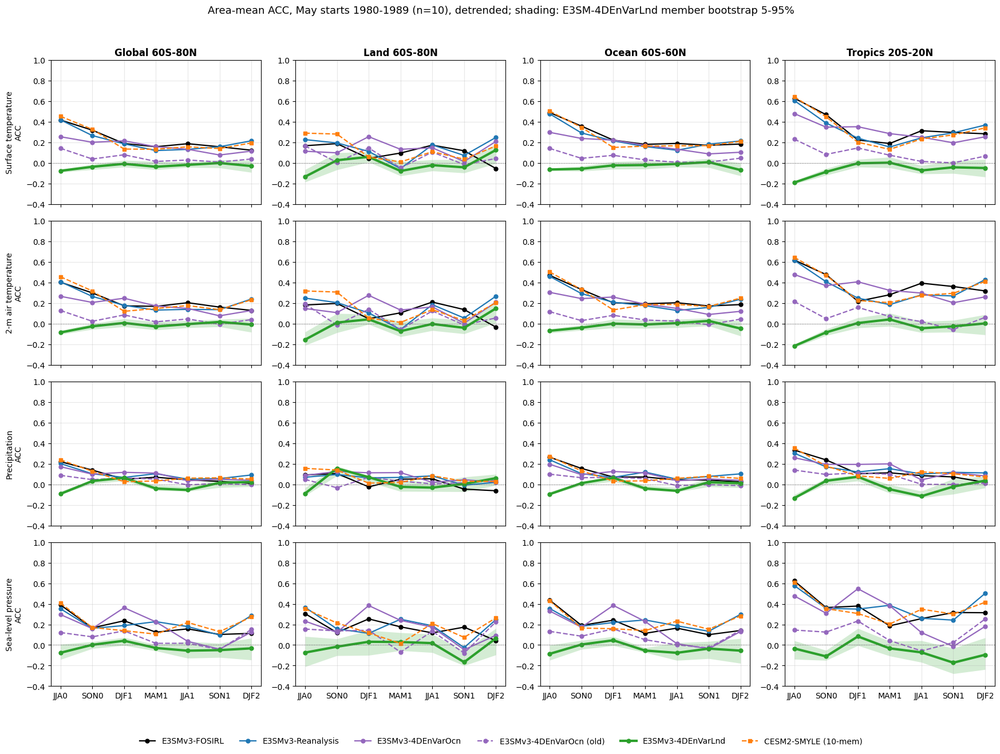

Saved /global/cfs/cdirs/e3sm/www/zhan391/e3sm-s2d_test/sample_figures/fig_fair_4DEnVarLnd_atm_area_mean_nrmse.png


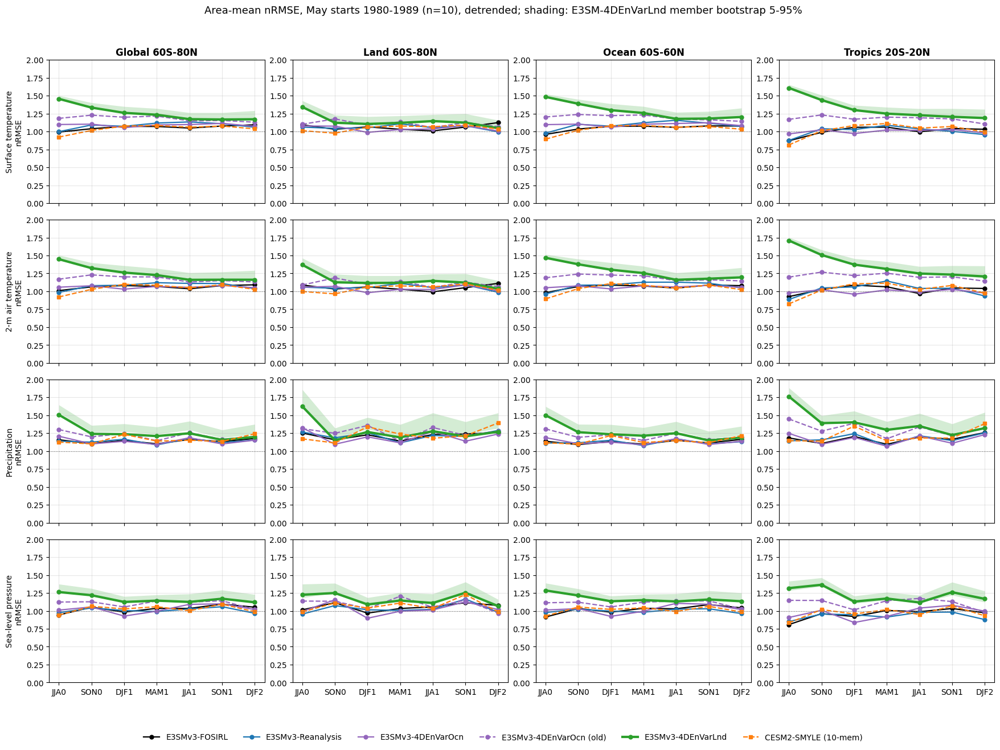

In [8]:
# -----------------------------------------------------------------------------
# Figure 01a/01b: area-mean ACC and nRMSE vs. lead (rows: fields, columns: regions)
# Shading = member-bootstrap range for the focus case (others omitted for legibility).
# -----------------------------------------------------------------------------
SHADE_KEYS = [FOCUS_CASE]


def area_lead_figure(metric, ylabel, ylim, ref_line, filename):
    nrow, ncol = len(ATM_FIELDS), len(AREA_REGIONS)
    fig, axes = plt.subplots(nrow, ncol, figsize=(4.4 * ncol, 3.2 * nrow), sharex=True, squeeze=False)
    for r, field in enumerate(ATM_FIELDS):
        x = np.arange(len(LEAD_LABELS[field]))
        for c, region in enumerate(AREA_REGIONS):
            ax = axes[r, c]
            for key in SOURCES:
                central, lo, hi = area_boot[(field, region, key, metric)]
                kw = style(key)
                lw = 3.0 if key == FOCUS_CASE else 1.6
                ax.plot(x, central, lw=lw, ms=5, **kw)
                if key in SHADE_KEYS:
                    ax.fill_between(x, lo, hi, color=kw["color"], alpha=0.2, lw=0)
            ax.axhline(ref_line, color="0.4", lw=0.8, ls=":")
            ax.set_ylim(*ylim)
            ax.grid(alpha=0.3)
            if r == 0:
                ax.set_title(region, fontsize=12, fontweight="bold")
            if c == 0:
                ax.set_ylabel(f"{FIELD_INFO[field]['name']}\n{ylabel}")
            ax.set_xticks(x, LEAD_LABELS[field])
    handles, labels = axes[0, 0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="lower center", ncol=len(labels), frameon=False, bbox_to_anchor=(0.5, -0.02))
    fig.suptitle(f"Area-mean {ylabel}, May starts {YEARS[0]}-{YEARS[1]} (n={len(YEAR_LIST)}), "
                 f"{'detrended' if DETREND else 'not detrended'}; shading: {FOCUS_CASE} member bootstrap "
                 f"{BOOT_PERCENTILES[0]}-{BOOT_PERCENTILES[1]}%", fontsize=13, y=1.0)
    fig.tight_layout(rect=(0, 0.04, 1, 0.98))
    save(fig, filename)
    plt.show()


area_lead_figure("corr", "ACC", (-0.4, 1.0), 0.0, f"fig_fair_{FOCUS_TAG}_atm_area_mean_acc.png")
area_lead_figure("rmse", "nRMSE", (0.0, 2.0), 1.0, f"fig_fair_{FOCUS_TAG}_atm_area_mean_nrmse.png")

Saved /global/cfs/cdirs/e3sm/www/zhan391/e3sm-s2d_test/sample_figures/fig_fair_4DEnVarLnd_atm_ts_acc_maps.png


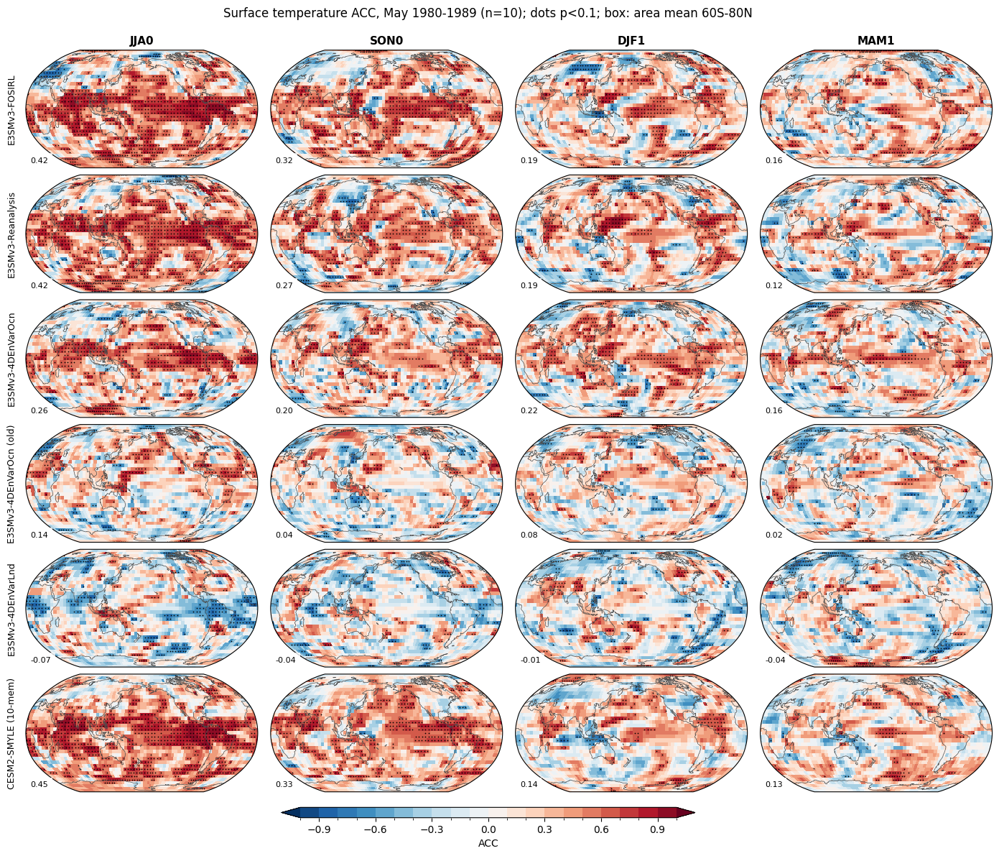

Saved /global/cfs/cdirs/e3sm/www/zhan391/e3sm-s2d_test/sample_figures/fig_fair_4DEnVarLnd_atm_ts_acc_difference_maps.png


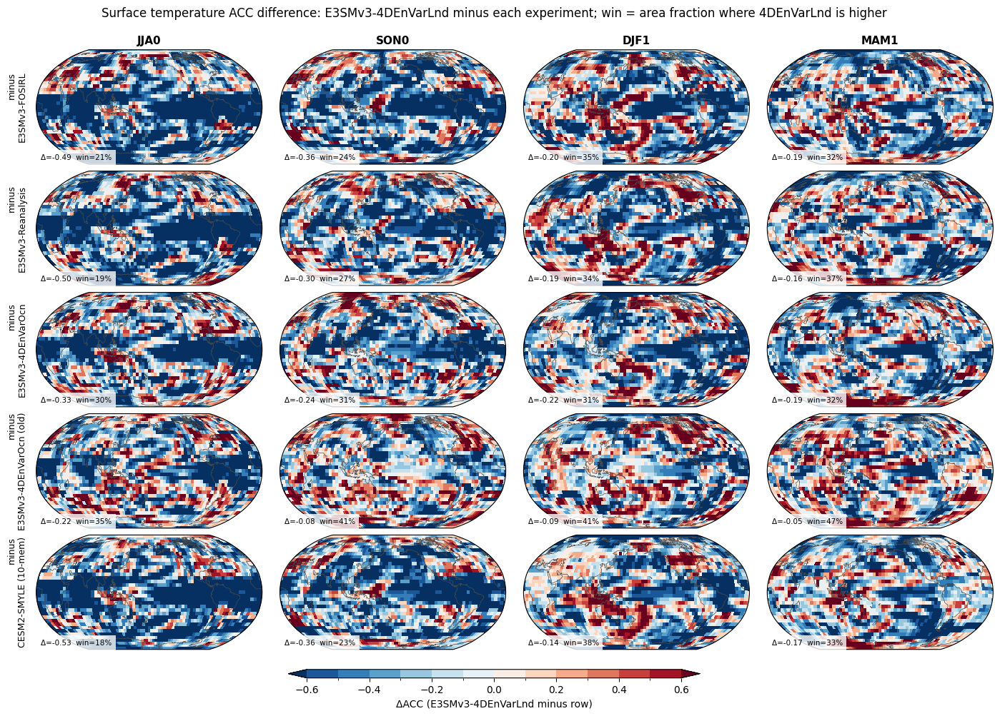

Saved /global/cfs/cdirs/e3sm/www/zhan391/e3sm-s2d_test/sample_figures/fig_fair_4DEnVarLnd_atm_trefht_acc_maps.png


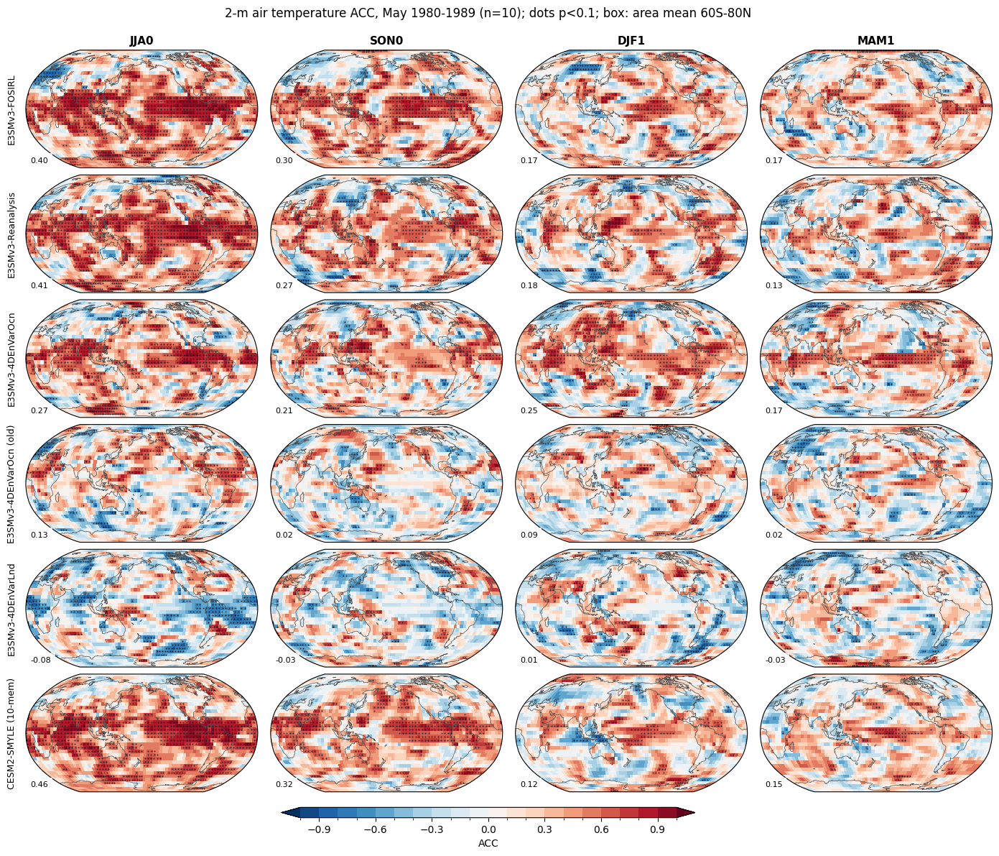

Saved /global/cfs/cdirs/e3sm/www/zhan391/e3sm-s2d_test/sample_figures/fig_fair_4DEnVarLnd_atm_trefht_acc_difference_maps.png


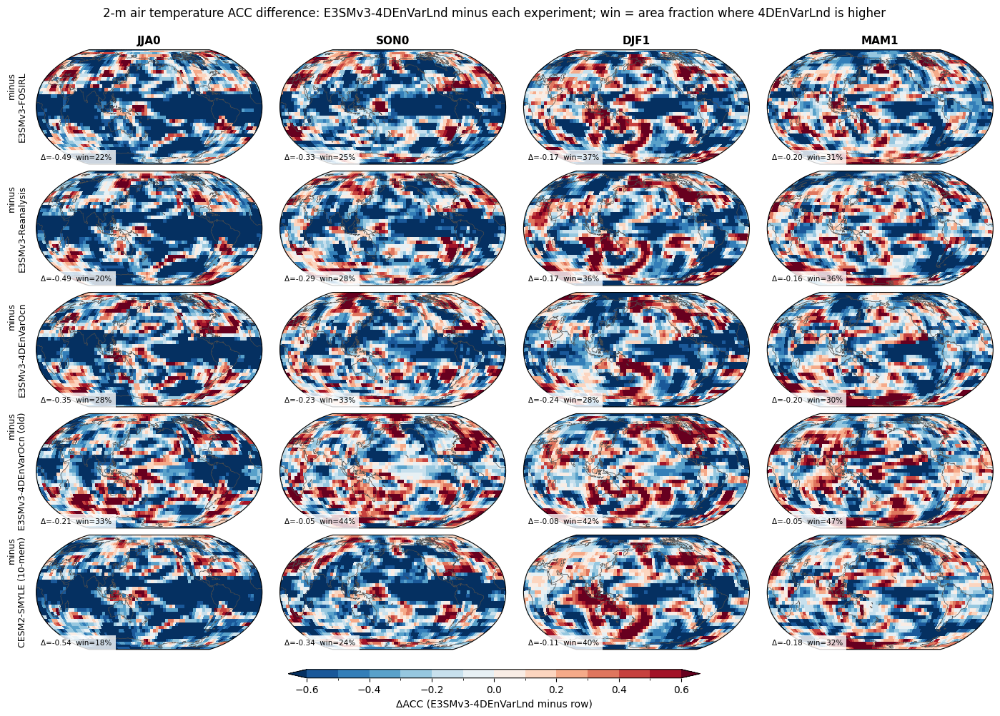

Saved /global/cfs/cdirs/e3sm/www/zhan391/e3sm-s2d_test/sample_figures/fig_fair_4DEnVarLnd_atm_prect_acc_maps.png


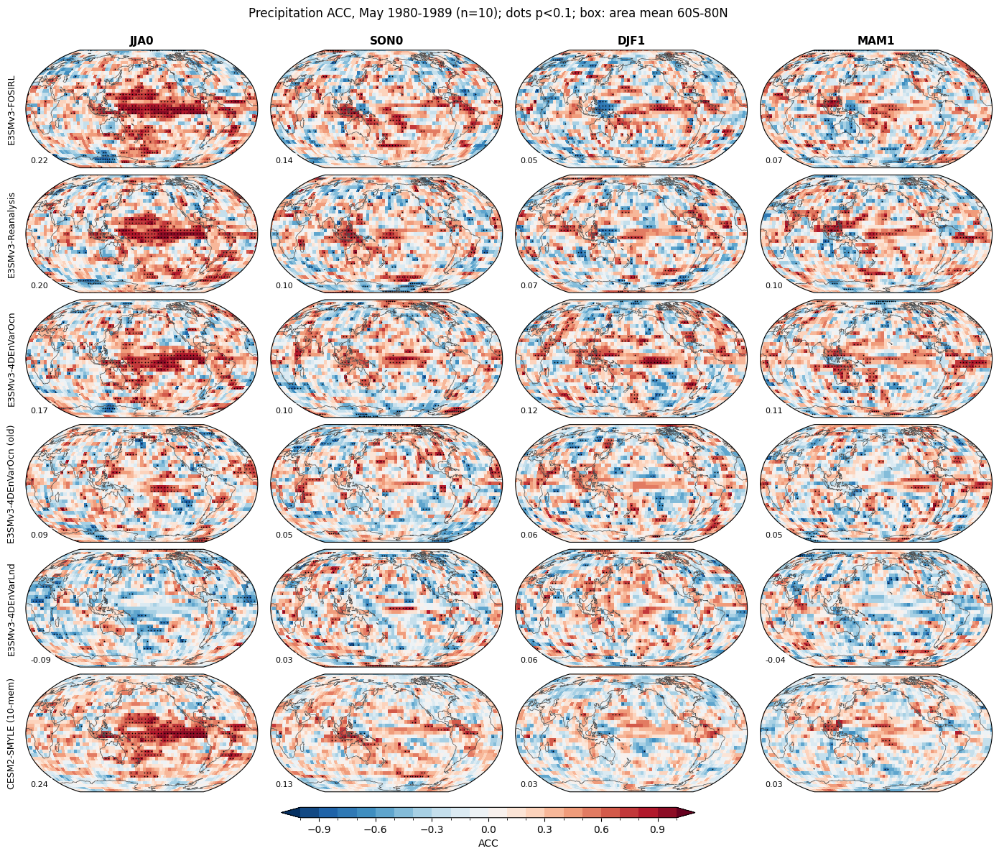

Saved /global/cfs/cdirs/e3sm/www/zhan391/e3sm-s2d_test/sample_figures/fig_fair_4DEnVarLnd_atm_prect_acc_difference_maps.png


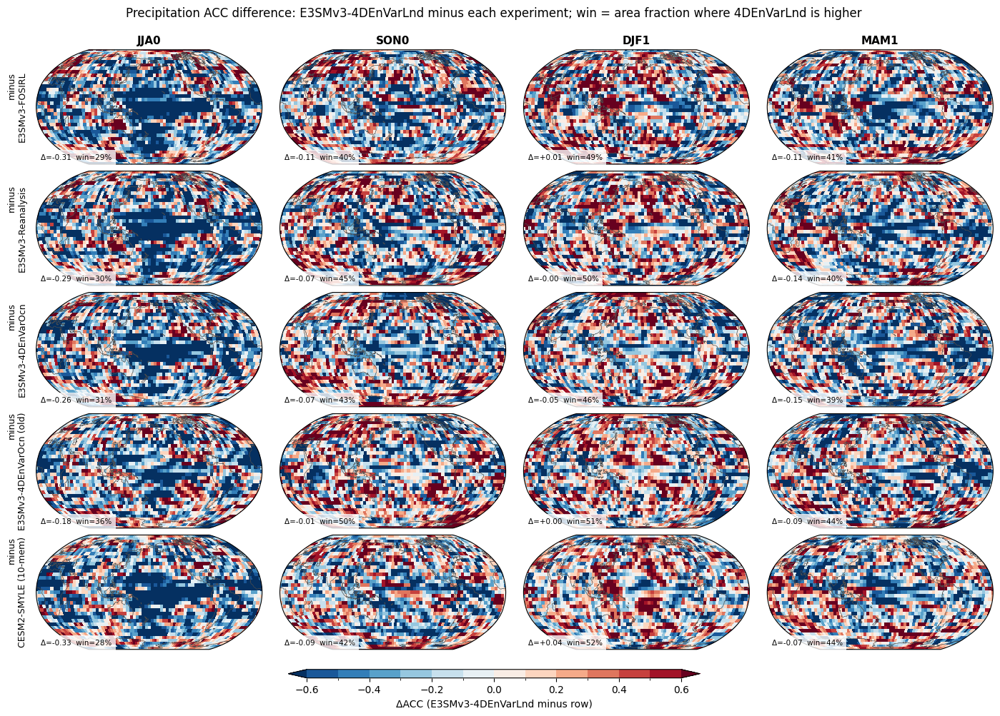

Saved /global/cfs/cdirs/e3sm/www/zhan391/e3sm-s2d_test/sample_figures/fig_fair_4DEnVarLnd_atm_psl_acc_maps.png


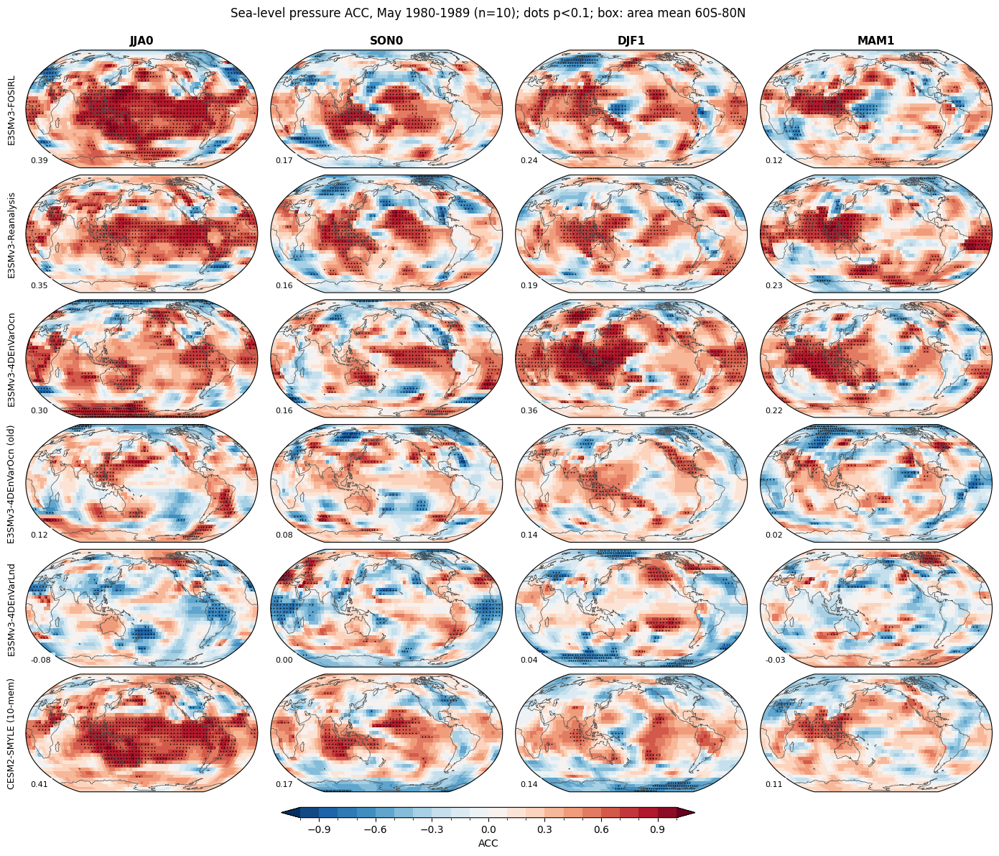

Saved /global/cfs/cdirs/e3sm/www/zhan391/e3sm-s2d_test/sample_figures/fig_fair_4DEnVarLnd_atm_psl_acc_difference_maps.png


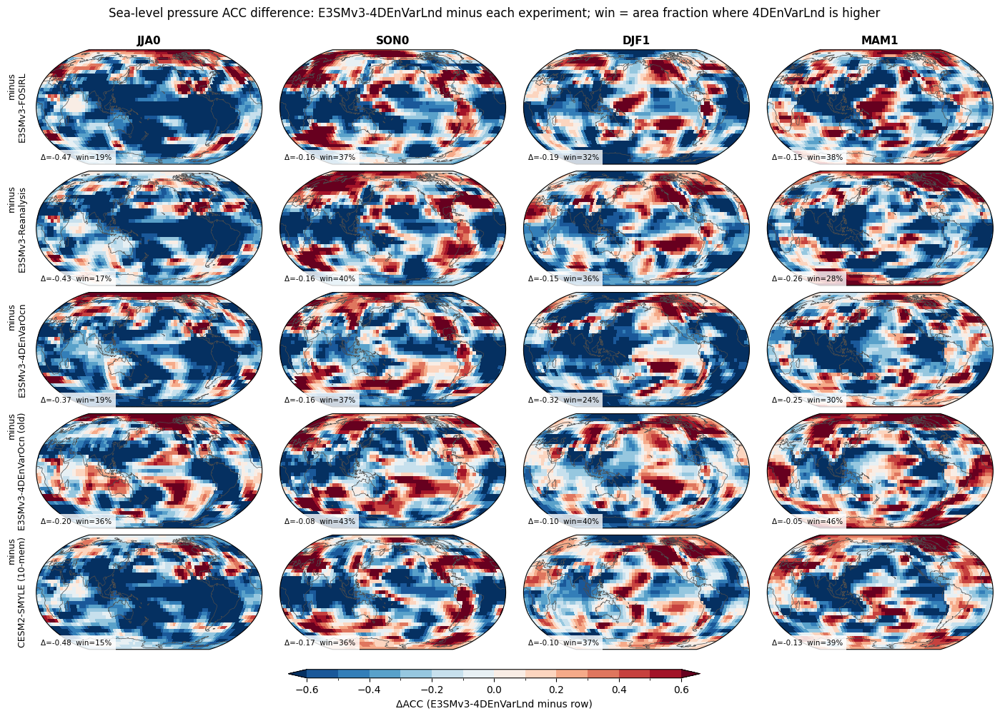

In [9]:
# -----------------------------------------------------------------------------
# Figure 01c: ACC maps (rows: experiments, columns: first MAP_LEADS seasons), dots = p < SIG_LEVEL
# Figure 01d: ACC difference maps, FOCUS_CASE minus each other experiment
# -----------------------------------------------------------------------------
PROJ = ccrs.Robinson(central_longitude=180)
ACC_LEVELS = np.arange(-1.0, 1.01, 0.1)
DIFF_LEVELS = np.arange(-0.6, 0.61, 0.1)


def _map(ax, da, levels, cmap):
    da = da.transpose("lat", "lon")
    data, lon = add_cyclic_point(da.values, coord=da.lon.values)
    norm = mcolors.BoundaryNorm(levels, plt.get_cmap(cmap).N, extend="both")
    pm = ax.pcolormesh(lon, da.lat.values, data, cmap=cmap, norm=norm, transform=ccrs.PlateCarree(), shading="auto")
    ax.coastlines(lw=0.5, color="0.3")
    ax.set_global()
    return pm


def _dots(ax, pval):
    pval = pval.transpose("lat", "lon")
    sig = pval < SIG_LEVEL
    lon2, lat2 = np.meshgrid(pval.lon.values, pval.lat.values)
    ax.scatter(lon2[sig.values], lat2[sig.values], s=1.5, c="k", transform=ccrs.PlateCarree(), linewidths=0)


for field in ATM_FIELDS:
    nlead = min(MAP_LEADS, len(LEAD_LABELS[field]))
    keys = list(SOURCES)
    fig, axes = plt.subplots(len(keys), nlead, figsize=(3.6 * nlead, 2.0 * len(keys)),
                             subplot_kw={"projection": PROJ}, squeeze=False)
    for r, key in enumerate(keys):
        sk = skill_maps[field][key]
        for c in range(nlead):
            ax = axes[r, c]
            pm = _map(ax, sk["corr"].isel(L=c), ACC_LEVELS, "RdBu_r")
            _dots(ax, sk["pval"].isel(L=c))
            gm = float(area_mean(sk["corr"].isel(L=c), "Global 60S-80N"))
            ax.text(0.02, 0.04, f"{gm:.2f}", transform=ax.transAxes, fontsize=8,
                    bbox=dict(fc="white", ec="none", alpha=0.8))
            if r == 0:
                ax.set_title(LEAD_LABELS[field][c], fontsize=11, fontweight="bold")
            if c == 0:
                ax.text(-0.04, 0.5, SOURCES[key]["label"], transform=ax.transAxes, rotation=90,
                        ha="right", va="center", fontsize=9)
    cax = fig.add_axes([0.3, 0.04, 0.4, 0.012])
    fig.colorbar(pm, cax=cax, orientation="horizontal", label="ACC")
    fig.suptitle(f"{FIELD_INFO[field]['name']} ACC, May {YEARS[0]}-{YEARS[1]} (n={len(YEAR_LIST)}); "
                 f"dots p<{SIG_LEVEL}; box: area mean 60S-80N", fontsize=12)
    fig.subplots_adjust(left=0.05, right=0.99, top=0.93, bottom=0.07, wspace=0.03, hspace=0.06)
    save(fig, f"fig_fair_{FOCUS_TAG}_atm_{field.lower()}_acc_maps.png")
    plt.show()

    others = [k for k in SOURCES if k != FOCUS_CASE]
    fig, axes = plt.subplots(len(others), nlead, figsize=(3.6 * nlead, 2.0 * len(others)),
                             subplot_kw={"projection": PROJ}, squeeze=False)
    focus = skill_maps[field][FOCUS_CASE]["corr"]
    for r, key in enumerate(others):
        diff = focus - skill_maps[field][key]["corr"]
        for c in range(nlead):
            ax = axes[r, c]
            d = diff.isel(L=c)
            pm = _map(ax, d, DIFF_LEVELS, "RdBu_r")
            win = float(area_mean((d > 0).astype(float).where(d.notnull()), "Global 60S-80N"))
            ax.text(0.02, 0.04, f"Δ={float(area_mean(d, 'Global 60S-80N')):+.2f}  win={win:.0%}",
                    transform=ax.transAxes, fontsize=7.5, bbox=dict(fc="white", ec="none", alpha=0.8))
            if r == 0:
                ax.set_title(LEAD_LABELS[field][c], fontsize=11, fontweight="bold")
            if c == 0:
                ax.text(-0.04, 0.5, f"minus\n{SOURCES[key]['label']}", transform=ax.transAxes, rotation=90,
                        ha="right", va="center", fontsize=9)
    cax = fig.add_axes([0.3, 0.04, 0.4, 0.012])
    fig.colorbar(pm, cax=cax, orientation="horizontal", label=f"ΔACC ({SOURCES[FOCUS_CASE]['label']} minus row)")
    fig.suptitle(f"{FIELD_INFO[field]['name']} ACC difference: {SOURCES[FOCUS_CASE]['label']} minus each experiment; "
                 f"win = area fraction where {FOCUS_TAG} is higher", fontsize=12)
    fig.subplots_adjust(left=0.05, right=0.99, top=0.92, bottom=0.08, wspace=0.03, hspace=0.06)
    save(fig, f"fig_fair_{FOCUS_TAG}_atm_{field.lower()}_acc_difference_maps.png")
    plt.show()

## Part 03 — regional SST-index skill (3a metrics)

Regional SST-index series are reused from the 3a caches when a current file covers 1980–1989 (any year span
that contains the cohort; the cohort is selected from it). Missing series, e.g. for 4DEnVarLnd, are built
with the same processor 3a uses (`scripts/run_process_sst_index.py`) and written under the test root.

In [10]:
# -----------------------------------------------------------------------------
# Ensure SST-index series for every source and index
# -----------------------------------------------------------------------------
import esp_lab
_repo = next(p for p in (Path.cwd(), *Path.cwd().parents, Path(esp_lab.__file__).resolve().parents[1])
             if (p / "scripts" / "run_process_sst_index.py").is_file())
_spec = importlib.util.spec_from_file_location("run_process_sst_index", _repo / "scripts" / "run_process_sst_index.py")
sst_index_processor = importlib.util.module_from_spec(_spec)
_spec.loader.exec_module(sst_index_processor)
logging.getLogger(sst_index_processor.__name__).setLevel(logging.INFO)


def sst_args(**overrides):
    values = dict(
        sources=["obs", "e3sm", "smyle"], regions=list(SST_INDICES), outdir=str(S2D_DIAG_ROOT),
        e3sm_data_dir=RAW_MODEL_ROOT, e3sm_case_prefix=None, e3sm_cache_tag=None, e3sm_display_name=None,
        e3sm_field=SST_FIELD, smyle_outdir=str(S2D_DIAG_ROOT / "CESM-SMYLE"),
        smyle_data_dir="/global/cfs/cdirs/e3sm/S2S2D/CESM-SMYLE", smyle_benchmark_dir=str(SMYLE_BENCHMARK_DIR),
        obs_outdir=str(S2D_DIAG_ROOT / "observations" / "sst_index" / "timeseries"),
        init_months=[INIT_MONTH], e3sm_init_years={INIT_MONTH: YEAR_LIST}, year_start=YEARS[0], year_end=YEARS[1],
        climy0=CLIM0, climy1=CLIM1, nlead=NLEAD, e3sm_nens=NENS, smyle_nens=SMYLE["nens"], workers=4,
        custom_regions=None, force=FORCE_REBUILD, sst_land_mask=True, eli_grid="regridded",
    )
    values.update(overrides)
    return SimpleNamespace(**values)


def _current(path):
    return path.is_file() and sst_index_processor._output_is_current(path, sst_args())


def sst_index_path(key, index):
    # First current file (test root, then production) whose year span covers the cohort.
    if key == "obs":
        rel = Path("observations") / "sst_index" / "timeseries" / f"HadISST2_sst_{index}SST_seas.nc"
        candidates = [root / rel for root in READ_ROOTS]
    else:
        tag = SOURCES[key]["cache_tag"]
        nens = SMYLE["nens"] if key == "CESM-SMYLE" else NENS
        name = sst_index_filename(tag, INIT_MONTH, YEARS, nens, NLEAD, index=index, field=SST_FIELD, seasonal=True)
        candidates = [resolve_year_span_path(root / tag / "sst_index" / "timeseries" / name) for root in READ_ROOTS]
    if FORCE_REBUILD:
        candidates = candidates[:1]
    return next((p for p in candidates if _current(p)), None)


missing = {key: [i for i in SST_INDICES if sst_index_path(key, i) is None] for key in ["obs", *SOURCES]}
print("Missing SST-index series:", {k: v for k, v in missing.items() if v} or "none")
for key, indices in missing.items():
    if not indices:
        continue
    if key == "obs":
        sst_index_processor.process_obs(sst_args(regions=indices))
    elif key == "CESM-SMYLE":
        sst_index_processor.process_smyle(sst_args(regions=indices))
    else:
        info = SOURCES[key]
        sst_index_processor.process_e3sm(sst_args(
            regions=indices, e3sm_case_prefix=info["case_prefix"], e3sm_cache_tag=info["cache_tag"],
            e3sm_display_name=info["label"]))

SST_PATHS = {(key, i): sst_index_path(key, i) for key in ["obs", *SOURCES] for i in SST_INDICES}
still_missing = [k for k, p in SST_PATHS.items() if p is None]
if still_missing:
    raise FileNotFoundError(f"SST-index series still unavailable: {still_missing}")
for (key, i), p in SST_PATHS.items():
    if i == SST_INDICES[0]:
        print(f"{key:>22s}: {p.parent}")

Missing SST-index series: {'E3SM-4DEnVarOcn': ['Nino3', 'Nino4', 'Nino12', 'ONI', 'IOD', 'TNA', 'TSA', 'AtlNino', 'AtlMDR'], 'E3SM-4DEnVarOcn-OLD': ['Nino3', 'Nino4', 'Nino12', 'ONI', 'IOD', 'TNA', 'TSA', 'AtlNino', 'AtlMDR'], 'E3SM-4DEnVarLnd': ['Nino3', 'Nino4', 'Nino12', 'ONI', 'IOD', 'TNA', 'TSA', 'AtlNino', 'AtlMDR']}


/global/homes/z/zhan391/.conda/envs/e3sm_analysis/lib/python3.14/site-packages/distributed/client.py:3398: UserWarning: Sending large graph of size 9.95 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


/global/homes/z/zhan391/.conda/envs/e3sm_analysis/lib/python3.14/site-packages/numpy/lib/_nanfunctions_impl.py:2015: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/global/homes/z/zhan391/.conda/envs/e3sm_analysis/lib/python3.14/site-packages/numpy/lib/_nanfunctions_impl.py:2015: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


/global/homes/z/zhan391/.conda/envs/e3sm_analysis/lib/python3.14/site-packages/distributed/client.py:3398: UserWarning: Sending large graph of size 9.95 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


/global/homes/z/zhan391/.conda/envs/e3sm_analysis/lib/python3.14/site-packages/numpy/lib/_nanfunctions_impl.py:2015: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/global/homes/z/zhan391/.conda/envs/e3sm_analysis/lib/python3.14/site-packages/numpy/lib/_nanfunctions_impl.py:2015: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


/global/homes/z/zhan391/.conda/envs/e3sm_analysis/lib/python3.14/site-packages/distributed/client.py:3398: UserWarning: Sending large graph of size 9.95 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


/global/homes/z/zhan391/.conda/envs/e3sm_analysis/lib/python3.14/site-packages/numpy/lib/_nanfunctions_impl.py:2015: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/global/homes/z/zhan391/.conda/envs/e3sm_analysis/lib/python3.14/site-packages/numpy/lib/_nanfunctions_impl.py:2015: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


                   obs: /global/cfs/cdirs/e3sm/S2S2D/s2d_diag/tmp/e3sm-s2d_test/observations/sst_index/timeseries
           E3SM-FOSIRL: /global/cfs/cdirs/e3sm/S2S2D/s2d_diag/tmp/e3sm-s2d_test/JRA55_FOSIRL/sst_index/timeseries
       E3SM-Reanalysis: /global/cfs/cdirs/e3sm/S2S2D/s2d_diag/tmp/e3sm-s2d_test/Reanalysis/sst_index/timeseries
       E3SM-4DEnVarOcn: /global/cfs/cdirs/e3sm/S2S2D/s2d_diag/tmp/e3sm-s2d_test/4DEnVarOcn/sst_index/timeseries
   E3SM-4DEnVarOcn-OLD: /global/cfs/cdirs/e3sm/S2S2D/s2d_diag/tmp/e3sm-s2d_test/4DEnVarOcn-OLD/sst_index/timeseries
       E3SM-4DEnVarLnd: /global/cfs/cdirs/e3sm/S2S2D/s2d_diag/tmp/e3sm-s2d_test/4DEnVarLnd/sst_index/timeseries
            CESM-SMYLE: /global/cfs/cdirs/e3sm/S2S2D/s2d_diag/tmp/e3sm-s2d_test/CESM-SMYLE/sst_index/timeseries


In [11]:
# -----------------------------------------------------------------------------
# SST-index skill: central estimate, SMYLE subsets, member bootstrap
# -----------------------------------------------------------------------------
def index_skill(key, index):
    obs = load_netcdf(SST_PATHS[("obs", index)])["sst"]
    ds = load_netcdf(SST_PATHS[(key, index)])
    data, time, _ = index_reference_skill.retain_complete_seasonal_leads(
        ds["sst"], ds["time"], label=f"{key} {index}", expected_count=NLEAD // 3 - 1)
    data, time = index_reference_skill.subset_hindcast_initialization_years(data, time, *YEARS)
    anom, _ = stats.remove_drift(data, time, CLIM0, CLIM1)
    nlead = anom.sizes["L"]
    if key == "CESM-SMYLE":
        central = stats.compute_skill_seasonal_batch(
            anom, time, obs, CLIM0, CLIM1, member_indices_all=SMYLE_SUBSETS, nleads=nlead,
            detrend=DETREND, metrics=("corr", "pval", "rmse")).mean("iteration")
    else:
        central = index_reference_skill.compute_reference_skill(
            anom, time, {"HadISST2": (obs, False)}, CLIM0, CLIM1, nleads=nlead, detrend=DETREND,
            monthly=False).sel(reference="HadISST2", drop=True)
    boot = stats.compute_skill_seasonal_batch(
        anom, time, obs, CLIM0, CLIM1, member_indices_all=BOOT_INDICES[anom.sizes["M"]], nleads=nlead,
        detrend=DETREND, metrics=("corr", "rmse"))
    return central[["corr", "pval", "rmse"]].load(), boot.load(), lead_labels(time)


index_central, index_boot, INDEX_LEADS = {}, {}, None
rows = []
for index in SST_INDICES:
    for key in SOURCES:
        c, b, INDEX_LEADS = index_skill(key, index)
        index_central[(key, index)], index_boot[(key, index)] = c, b
        for metric in ("corr", "rmse"):
            lo, hi = (b[metric].quantile(q / 100, "iteration") for q in BOOT_PERCENTILES)
            for i, L in enumerate(c.L.values):
                rows.append(dict(index=index, experiment=SOURCES[key]["label"], key=key,
                                 metric={"corr": "ACC", "rmse": "nRMSE"}[metric], lead=INDEX_LEADS[i], L=int(L),
                                 value=float(c[metric].sel(L=L)), p_lo=float(lo.sel(L=L)), p_hi=float(hi.sel(L=L)),
                                 pval=float(c["pval"].sel(L=L))))
sst_table = pd.DataFrame(rows)
sst_table_path = TABLE_DIR / f"multimodel_init{INIT_MONTH:02d}_sst_index_skill_fair_{SPAN}.csv"
sst_table.to_csv(sst_table_path, index=False)
print(f"Saved {sst_table_path}")

# Seasonal ACC table for the first index (rows: lead season; columns: experiments)
sst_table[(sst_table["metric"] == "ACC") & (sst_table["index"] == SST_INDICES[0])].pivot_table(
    index="lead", columns="experiment", values="value", sort=False).round(2)

Saved /global/cfs/cdirs/e3sm/S2S2D/s2d_diag/tmp/e3sm-s2d_test/multimodel/fair_compare/multimodel_init05_sst_index_skill_fair_y1980-1989.csv


experiment,E3SMv3-FOSIRL,E3SMv3-Reanalysis,E3SMv3-4DEnVarOcn,E3SMv3-4DEnVarOcn (old),E3SMv3-4DEnVarLnd,CESM2-SMYLE (10-mem)
lead,,,,,,
JJA0,0.82,0.79,0.57,0.17,-0.26,0.78
SON0,0.77,0.62,0.58,0.15,0.10,0.61
DJF1,0.82,0.66,0.67,0.33,0.01,0.66
MAM1,0.75,0.66,0.81,0.59,-0.20,0.76
JJA1,0.72,0.76,0.74,-0.10,-0.33,0.79
SON1,0.69,0.77,0.46,0.00,0.07,0.81
DJF2,0.74,0.90,0.44,0.06,-0.15,0.88


Saved /global/cfs/cdirs/e3sm/www/zhan391/e3sm-s2d_test/sample_figures/fig_fair_4DEnVarLnd_sst_index_acc.png


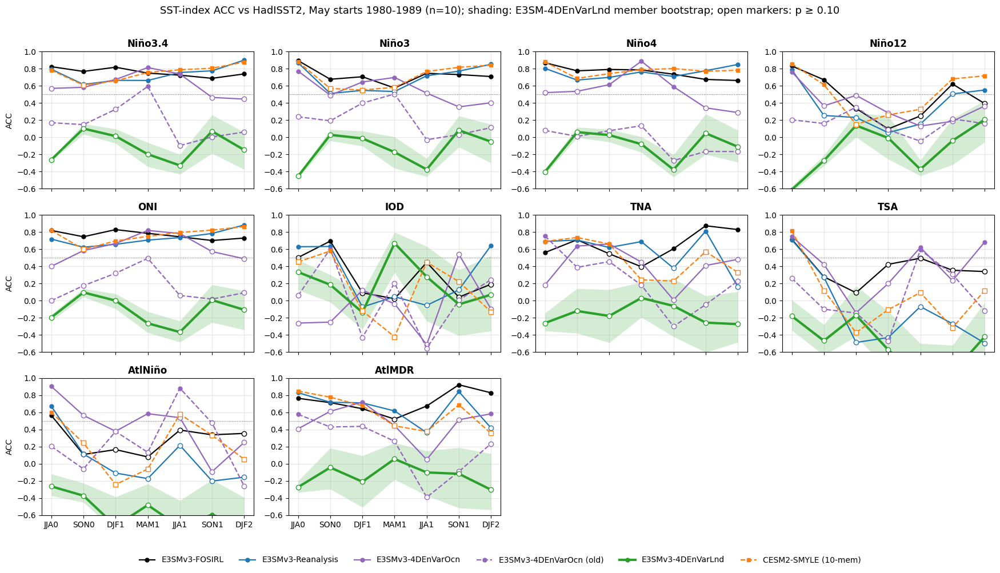

Saved /global/cfs/cdirs/e3sm/www/zhan391/e3sm-s2d_test/sample_figures/fig_fair_4DEnVarLnd_sst_index_nrmse.png


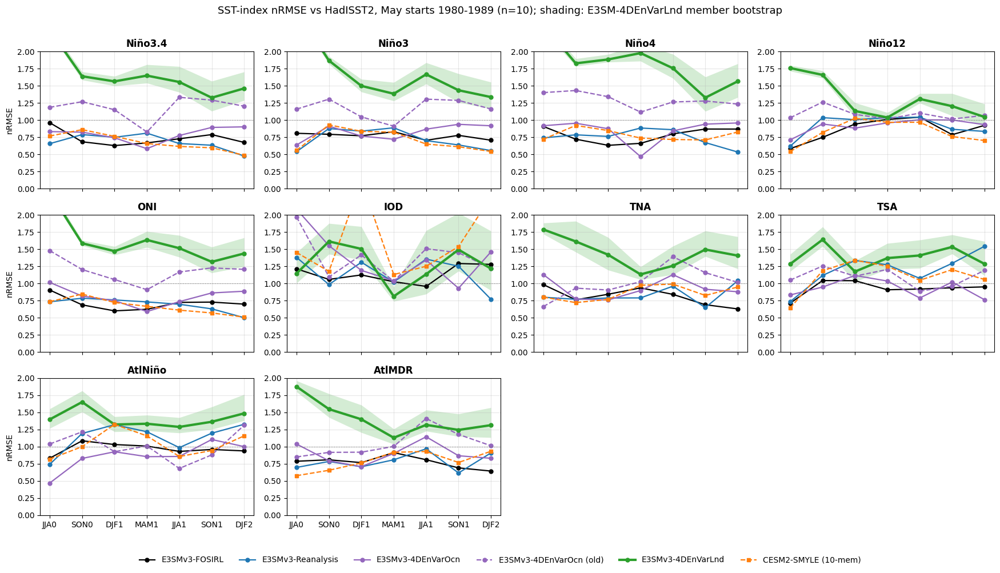

In [12]:
# -----------------------------------------------------------------------------
# Figure 03a/03b: SST-index ACC and nRMSE vs. lead (one panel per index)
# -----------------------------------------------------------------------------
def index_lead_figure(metric, ylabel, ylim, ref_line, filename, ncol=4):
    nrow = int(np.ceil(len(SST_INDICES) / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(4.4 * ncol, 3.3 * nrow), sharex=True, squeeze=False)
    x = np.arange(len(INDEX_LEADS))
    for n, index in enumerate(SST_INDICES):
        ax = axes.flat[n]
        for key in SOURCES:
            c, b = index_central[(key, index)], index_boot[(key, index)]
            kw = style(key)
            lw = 3.0 if key == FOCUS_CASE else 1.6
            ax.plot(x, c[metric], lw=lw, ms=5, **kw)
            if metric == "corr":   # filled marker = significant (p < SIG_LEVEL), as in 3a
                sig = (c["pval"] < SIG_LEVEL).values
                ax.plot(x[~sig], c[metric].values[~sig], ls="none", marker=kw["marker"], ms=6,
                        mfc="white", mec=kw["color"])
            if key in SHADE_KEYS:
                lo, hi = (b[metric].quantile(q / 100, "iteration") for q in BOOT_PERCENTILES)
                ax.fill_between(x, lo, hi, color=kw["color"], alpha=0.2, lw=0)
        ax.axhline(ref_line, color="0.4", lw=0.8, ls=":")
        ax.set_ylim(*ylim)
        ax.set_title(index.replace("Nino", "Niño"), fontsize=12, fontweight="bold")
        ax.grid(alpha=0.3)
        ax.set_xticks(x, INDEX_LEADS)
        if n % ncol == 0:
            ax.set_ylabel(ylabel)
    for ax in axes.flat[len(SST_INDICES):]:
        ax.set_visible(False)
    handles, labels = axes.flat[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="lower center", ncol=len(labels), frameon=False, bbox_to_anchor=(0.5, -0.02))
    note = "; open markers: p ≥ %.2f" % SIG_LEVEL if metric == "corr" else ""
    fig.suptitle(f"SST-index {ylabel} vs HadISST2, May starts {YEARS[0]}-{YEARS[1]} (n={len(YEAR_LIST)}); "
                 f"shading: {FOCUS_CASE} member bootstrap{note}", fontsize=13)
    fig.tight_layout(rect=(0, 0.04, 1, 0.97))
    save(fig, filename)
    plt.show()


index_lead_figure("corr", "ACC", (-0.6, 1.0), 0.5, f"fig_fair_{FOCUS_TAG}_sst_index_acc.png")
index_lead_figure("rmse", "nRMSE", (0.0, 2.0), 1.0, f"fig_fair_{FOCUS_TAG}_sst_index_nrmse.png")

## Scorecard — 4DEnVarLnd minus each experiment

Lead-averaged differences (all available seasonal leads). For ACC, positive (red) means 4DEnVarLnd is more
skillful. For nRMSE the sign is flipped (other minus 4DEnVarLnd) so that red again means 4DEnVarLnd is
better. `*` marks differences whose sign holds in at least 90% of paired member-bootstrap draws.
Because the draws share year samples, this test covers only ensemble-size noise, not year-sampling noise.

Saved /global/cfs/cdirs/e3sm/S2S2D/s2d_diag/tmp/e3sm-s2d_test/multimodel/fair_compare/multimodel_init05_4DEnVarLnd_scorecard_fair_y1980-1989.csv


Saved /global/cfs/cdirs/e3sm/www/zhan391/e3sm-s2d_test/sample_figures/fig_fair_4DEnVarLnd_scorecard.png


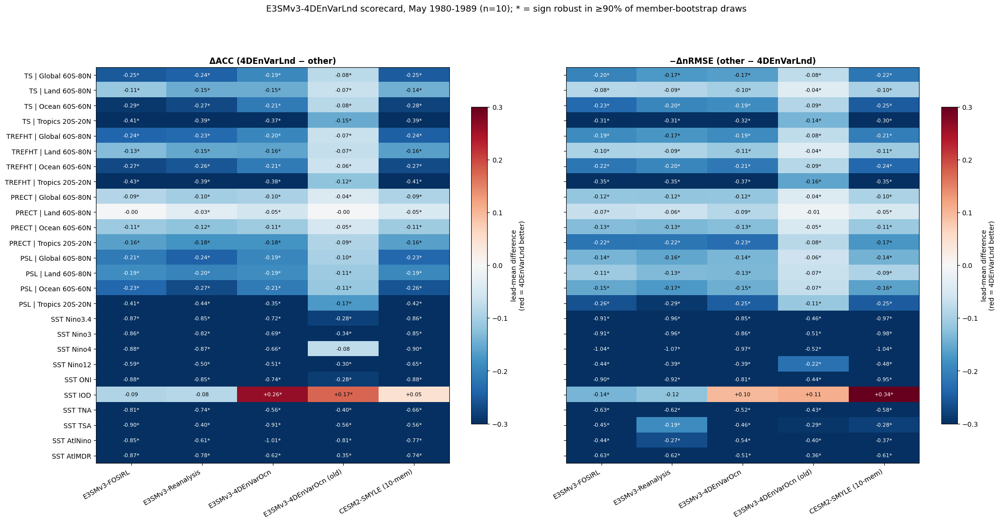

In [13]:
# -----------------------------------------------------------------------------
# Scorecard heatmap: rows = field/region (01) and SST index (03); columns = other experiments
# -----------------------------------------------------------------------------
others = [k for k in SOURCES if k != FOCUS_CASE]


def _score(central_focus, central_other, boot_focus, boot_other, metric):
    sign = 1.0 if metric == "corr" else -1.0
    diff = sign * float((central_focus - central_other).mean("L"))
    boot = sign * (boot_focus - boot_other).mean("L")
    robust = float((np.sign(boot) == np.sign(diff)).mean()) >= 0.9
    return diff, robust


score_rows = []
for metric in ("corr", "rmse"):
    for field in ATM_FIELDS:
        for region in AREA_REGIONS:
            fb = area_mean(skill_boot[field][FOCUS_CASE][metric], region)
            fc = area_boot[(field, region, FOCUS_CASE, metric)][0]
            for key in others:
                ob = area_mean(skill_boot[field][key][metric], region)
                oc = area_boot[(field, region, key, metric)][0]
                d, robust = _score(fc, oc, fb, ob, metric)
                score_rows.append(dict(metric=metric, row=f"{field} | {region}", other=SOURCES[key]["label"],
                                       diff=d, robust=robust))
    for index in SST_INDICES:
        fc, fb = index_central[(FOCUS_CASE, index)][metric], index_boot[(FOCUS_CASE, index)][metric]
        for key in others:
            oc, ob = index_central[(key, index)][metric], index_boot[(key, index)][metric]
            d, robust = _score(fc, oc, fb, ob, metric)
            score_rows.append(dict(metric=metric, row=f"SST {index}", other=SOURCES[key]["label"],
                                   diff=d, robust=robust))
scorecard = pd.DataFrame(score_rows)
scorecard_path = TABLE_DIR / f"multimodel_init{INIT_MONTH:02d}_{FOCUS_TAG}_scorecard_fair_{SPAN}.csv"
scorecard.to_csv(scorecard_path, index=False)
print(f"Saved {scorecard_path}")

fig, axes = plt.subplots(1, 2, figsize=(5 + 1.6 * len(others) * 2, 0.32 * scorecard.row.nunique() + 2.5))
for ax, metric, title in zip(axes, ("corr", "rmse"), ("ΔACC (4DEnVarLnd − other)", "−ΔnRMSE (other − 4DEnVarLnd)")):
    sub = scorecard[scorecard.metric == metric]
    val = sub.pivot(index="row", columns="other", values="diff").loc[sub.row.unique(), [SOURCES[k]["label"] for k in others]]
    rob = sub.pivot(index="row", columns="other", values="robust").loc[val.index, val.columns]
    vmax = 0.3
    im = ax.imshow(val.values, cmap="RdBu_r", vmin=-vmax, vmax=vmax, aspect="auto")
    for (i, j), v in np.ndenumerate(val.values):
        ax.text(j, i, f"{v:+.2f}{'*' if rob.values[i, j] else ''}", ha="center", va="center", fontsize=8,
                color="white" if abs(v) > 0.6 * vmax else "black")
    ax.set_xticks(range(len(val.columns)), val.columns, rotation=30, ha="right")
    ax.set_yticks(range(len(val.index)), val.index if metric == "corr" else [])
    ax.set_title(title, fontsize=12, fontweight="bold")
    fig.colorbar(im, ax=ax, shrink=0.8, label="lead-mean difference\n(red = 4DEnVarLnd better)")
fig.suptitle(f"{SOURCES[FOCUS_CASE]['label']} scorecard, May {YEARS[0]}-{YEARS[1]} (n={len(YEAR_LIST)}); "
             "* = sign robust in ≥90% of member-bootstrap draws", fontsize=13, y=0.995)
fig.tight_layout(rect=(0, 0, 1, 0.94))
save(fig, f"fig_fair_{FOCUS_TAG}_scorecard.png")
plt.show()

In [14]:
# Close this kernel's Dask clients and owned clusters.
close_notebook_resources(globals())